Cell 1: Combine all live snapshots

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cities = list(yaml.safe_load(open(ROOT / "params.yaml"))["data"]["cities"])

files = sorted((ROOT / "data" / "raw" / "live" / "datagov").glob("*/*.csv"))
live = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)
live["city"] = live["city"].str.strip()
live["last_update"] = pd.to_datetime(live["last_update"], format="%d-%m-%Y %H:%M:%S")
for c in ["min_value", "max_value", "avg_value"]:
    live[c] = pd.to_numeric(live[c], errors="coerce")
print(len(files), "snapshots |", len(live), "rows | distinct reading hours:",
      live["last_update"].nunique())

live = (live[live["city"].isin(cities)]
        .sort_values("fetched_at_utc")
        .drop_duplicates(["station", "last_update"])
        .sort_values(["station", "last_update"])
        .reset_index(drop=True))
print("rows after keeping our 14 cities and removing repeats:", len(live))
print(live.groupby("station").size().describe().round(1))

9 snapshots | 4565 rows | distinct reading hours: 8
rows after keeping our 14 cities and removing repeats: 1243
count    156.0
mean       8.0
std        0.3
min        5.0
25%        8.0
50%        8.0
75%        8.0
max        8.0
dtype: float64


Cell 2: How the live values behave from hour to hour

In [2]:
g = live.groupby("station")
live["gap_h"] = g["last_update"].diff().dt.total_seconds() / 3600
live["d_avg"] = g["avg_value"].diff().abs()
live["min_same"] = g["min_value"].diff() == 0
live["max_same"] = g["max_value"].diff() == 0

consec = live[live["gap_h"] == 1]
print("consecutive-hour pairs:", len(consec))
print("median |hour-to-hour change| of avg_value:", consec["d_avg"].median())
print("min_value unchanged from previous hour:", round(100 * consec["min_same"].mean(), 1), "%")
print("max_value unchanged from previous hour:", round(100 * consec["max_same"].mean(), 1), "%")

consecutive-hour pairs: 1087
median |hour-to-hour change| of avg_value: 1.0
min_value unchanged from previous hour: 75.5 %
max_value unchanged from previous hour: 81.7 %


Cell 3: Reference behaviour from the Kaggle data

In [3]:
RAW = ROOT / "data" / "raw" / "cpcb"
PM = "PM2.5 (ug/m3)"
st = pd.read_csv(RAW / "stations_info.csv")
st["city"] = st["city"].str.strip()

d_hourly, d_roll, max_same = [], [], []
for code in st.loc[st["city"].isin(cities), "file_name"]:
    df = pd.read_csv(RAW / f"{code}.csv", usecols=lambda c: c in ("From Date", PM))
    if PM not in df.columns:
        continue
    s = df.set_index(pd.to_datetime(df["From Date"]))[PM]
    s = s[~s.index.duplicated()].loc["2022-04-01":]
    if s.notna().sum() < 1000:
        continue
    s = s.asfreq("h")                        # one row per real hour, gaps as NaN
    roll_mean = s.rolling(24, min_periods=18).mean()
    roll_max = s.rolling(24, min_periods=18).max()
    d_hourly.append(s.diff().abs().dropna())
    d_roll.append(roll_mean.diff().abs().dropna())
    max_same.append(roll_max.diff().dropna().eq(0))

print("Kaggle reference (same 14 cities, Apr 2022 - Mar 2023):")
print("  median |change| of raw hourly values :", pd.concat(d_hourly).median())
print("  median |change| of 24-h rolling mean :", round(pd.concat(d_roll).median(), 2))
print("  24-h rolling max unchanged           :", round(100 * pd.concat(max_same).mean(), 1), "%")

Kaggle reference (same 14 cities, Apr 2022 - Mar 2023):
  median |change| of raw hourly values : 4.759999999999991
  median |change| of 24-h rolling mean : 0.51
  24-h rolling max unchanged           : 87.0 %


Cell 4: One station, visually

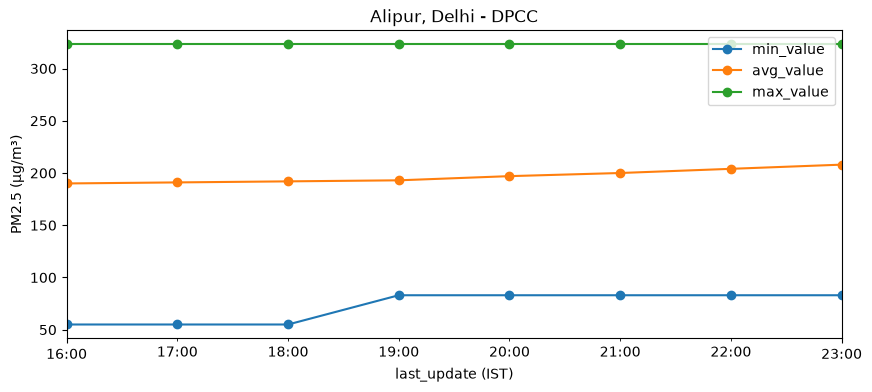

In [4]:
stn = live[live["city"] == "Delhi"].groupby("station").size().idxmax()
s = live[live["station"] == stn].set_index("last_update")
ax = s[["min_value", "avg_value", "max_value"]].plot(marker="o", figsize=(10, 4), title=stn)
ax.set(ylabel="PM2.5 (µg/m³)", xlabel="last_update (IST)")
plt.show()